In [12]:
import geopandas as gpd
import pandas as pd
import h3pandas

import matplotlib.pyplot as plt

from tobler.area_weighted import area_interpolate
from libpysal.weights import Queen, lag_spatial
from esda.moran import Moran
import numpy as np

plt.rcParams['font.family'] = 'Times New Roman'

In [2]:
h3Res = [7, 8, 9, 10, 11]
sp = gpd.read_file("/Users/camillaperotto/Documents/pde-sp/01_AccessPipeline/data/sp.geojson")
poligono_sp = sp.iloc[0].geometry
years = ["2013", "2021"]

In [3]:
morans = {}
for y in years:
    morans[y] = []
    
    df1 = pd.read_csv(f"/Users/camillaperotto/Documents/pde-sp/01_AccessPipeline/data/address/_destinations__{y}.csv", usecols=["LATITUDE", "LONGITUDE", 'T001'], sep=';')
    df2 = pd.read_csv(f"/Users/camillaperotto/Documents/pde-sp/01_AccessPipeline/data/address/_destinations2__{y}.csv", usecols=["latitude", "longitude", 'T001'], sep=';')
    df2 = df2.rename(columns={"latitude": 'LATITUDE', "longitude": 'LONGITUDE'})
    df = pd.concat([df1, df2])
    del df1
    del df2

    for res in h3Res:
        _df = df.h3.geo_to_h3(res, lat_col='LATITUDE', lng_col='LONGITUDE').reset_index()
        #print(_df)
        
        _res = str(res)
        if len(_res)==1: _res = "0"+_res
        _df = _df.groupby(f"h3_{_res}").agg({'T001': 'sum'})

        _df = _df.h3.h3_to_geo_boundary()
        w = Queen.from_dataframe(_df)
        w.transform = 'r'

        moran = Moran(_df["T001"], w)
        #morans[y].append({'res': res, 'moran': moran.I})
        morans[y].append({
            "grid": res,
            "I": moran.I,
            "se": moran.seI_sim,  # erro padrão da simulação
            "IC_low": moran.EI_sim - 1.96 * moran.seI_sim,
            "IC_high": moran.EI_sim + 1.96 * moran.seI_sim
        })


    

/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_17213/4231050153.py:21: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(_df)
/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 324 disconnected components.
 There are 237 islands with ids: 0, 1, 2, 5, 6, 12, 13, 15, 16, 17, 18, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 35, 37, 41, 44, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 65, 321, 323, 341, 354, 364, 365, 395, 396, 397, 445, 473, 479, 487, 498, 499, 500, 501, 516, 517, 518, 519, 598, 601, 622, 636, 639, 644, 665, 672, 674, 675, 709, 712, 714, 716, 719, 720, 729, 741, 742, 757, 767, 773, 775, 776, 782, 783, 785, 793, 798, 799, 801, 802, 804, 809, 810, 815, 816, 834, 837, 840, 841, 845, 846, 854, 855, 858, 859,

('WARNING: ', 0, ' is an island (no neighbors)')
('WARNING: ', 1, ' is an island (no neighbors)')
('WARNING: ', 2, ' is an island (no neighbors)')
('WARNING: ', 5, ' is an island (no neighbors)')
('WARNING: ', 6, ' is an island (no neighbors)')
('WARNING: ', 12, ' is an island (no neighbors)')
('WARNING: ', 13, ' is an island (no neighbors)')
('WARNING: ', 15, ' is an island (no neighbors)')
('WARNING: ', 16, ' is an island (no neighbors)')
('WARNING: ', 17, ' is an island (no neighbors)')
('WARNING: ', 18, ' is an island (no neighbors)')
('WARNING: ', 21, ' is an island (no neighbors)')
('WARNING: ', 22, ' is an island (no neighbors)')
('WARNING: ', 23, ' is an island (no neighbors)')
('WARNING: ', 24, ' is an island (no neighbors)')
('WARNING: ', 25, ' is an island (no neighbors)')
('WARNING: ', 26, ' is an island (no neighbors)')
('WARNING: ', 27, ' is an island (no neighbors)')
('WARNING: ', 28, ' is an island (no neighbors)')
('WARNING: ', 29, ' is an island (no neighbors)')
('WAR

/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_17213/4231050153.py:21: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(_df)
/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 746 disconnected components.
 There are 580 islands with ids: 0, 1, 2, 3, 4, 5, 6, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 29, 30, 31, 32, 35, 36, 37, 38, 39, 40, 41, 43, 44, 45, 53, 54, 55, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 78, 79, 80, 310, 316, 317, 506, 514, 518, 664, 732, 780, 784, 1135, 1139, 1140, 1149, 1150, 1155, 1170, 1174, 1181, 1190, 1246, 1260, 1290, 1291, 1293, 1295, 1298, 1299, 1300, 1301, 1302, 1303, 1305, 1306, 1311, 1315, 1320, 1322, 1328, 1329, 1330, 1336, 1337, 1359, 1377, 1383, 1384, 1402, 1418, 1

('WARNING: ', 0, ' is an island (no neighbors)')
('WARNING: ', 1, ' is an island (no neighbors)')
('WARNING: ', 2, ' is an island (no neighbors)')
('WARNING: ', 3, ' is an island (no neighbors)')
('WARNING: ', 4, ' is an island (no neighbors)')
('WARNING: ', 5, ' is an island (no neighbors)')
('WARNING: ', 6, ' is an island (no neighbors)')
('WARNING: ', 12, ' is an island (no neighbors)')
('WARNING: ', 13, ' is an island (no neighbors)')
('WARNING: ', 14, ' is an island (no neighbors)')
('WARNING: ', 15, ' is an island (no neighbors)')
('WARNING: ', 16, ' is an island (no neighbors)')
('WARNING: ', 17, ' is an island (no neighbors)')
('WARNING: ', 18, ' is an island (no neighbors)')
('WARNING: ', 19, ' is an island (no neighbors)')
('WARNING: ', 20, ' is an island (no neighbors)')
('WARNING: ', 21, ' is an island (no neighbors)')
('WARNING: ', 22, ' is an island (no neighbors)')
('WARNING: ', 23, ' is an island (no neighbors)')
('WARNING: ', 24, ' is an island (no neighbors)')
('WARNI

/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_17213/4231050153.py:21: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(_df)
/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 1524 disconnected components.
 There are 1240 islands with ids: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 62, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 81, 82, 83, 84, 108, 152, 164, 199, 200, 215, 547, 550, 556, 558, 559, 582, 598, 599, 601, 605, 606, 608, 613, 664, 752, 803, 804, 809, 822, 894, 1122, 1123, 1124, 1125, 1126, 1127, 1130, 1131, 1132, 1149, 1276, 1322, 1332, 1333, 1346

('WARNING: ', 0, ' is an island (no neighbors)')
('WARNING: ', 1, ' is an island (no neighbors)')
('WARNING: ', 2, ' is an island (no neighbors)')
('WARNING: ', 3, ' is an island (no neighbors)')
('WARNING: ', 4, ' is an island (no neighbors)')
('WARNING: ', 5, ' is an island (no neighbors)')
('WARNING: ', 6, ' is an island (no neighbors)')
('WARNING: ', 7, ' is an island (no neighbors)')
('WARNING: ', 8, ' is an island (no neighbors)')
('WARNING: ', 9, ' is an island (no neighbors)')
('WARNING: ', 10, ' is an island (no neighbors)')
('WARNING: ', 14, ' is an island (no neighbors)')
('WARNING: ', 15, ' is an island (no neighbors)')
('WARNING: ', 16, ' is an island (no neighbors)')
('WARNING: ', 17, ' is an island (no neighbors)')
('WARNING: ', 18, ' is an island (no neighbors)')
('WARNING: ', 19, ' is an island (no neighbors)')
('WARNING: ', 20, ' is an island (no neighbors)')
('WARNING: ', 21, ' is an island (no neighbors)')
('WARNING: ', 22, ' is an island (no neighbors)')
('WARNING:

... (10 outputs left out)

/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_17213/4231050153.py:21: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(_df)
/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 2701 disconnected components.
 There are 2014 islands with ids: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 96, 100, 101, 103, 109, 116, 123, 124, 134, 200, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 259, 298, 301, 314, 318, 346, 347, 348, 350, 353, 373, 374, 375, 376, 692, 693, 698, 704, 705, 709, 1091, 1106, 1107, 1174, 1186, 1203, 1204, 1205, 1382, 1475, 1483, 1484, 1485, 1548, 1642, 1

('WARNING: ', 0, ' is an island (no neighbors)')
('WARNING: ', 1, ' is an island (no neighbors)')
('WARNING: ', 2, ' is an island (no neighbors)')
('WARNING: ', 3, ' is an island (no neighbors)')
('WARNING: ', 4, ' is an island (no neighbors)')
('WARNING: ', 5, ' is an island (no neighbors)')
('WARNING: ', 6, ' is an island (no neighbors)')
('WARNING: ', 7, ' is an island (no neighbors)')
('WARNING: ', 8, ' is an island (no neighbors)')
('WARNING: ', 9, ' is an island (no neighbors)')
('WARNING: ', 10, ' is an island (no neighbors)')
('WARNING: ', 11, ' is an island (no neighbors)')
('WARNING: ', 12, ' is an island (no neighbors)')
('WARNING: ', 13, ' is an island (no neighbors)')
('WARNING: ', 14, ' is an island (no neighbors)')
('WARNING: ', 15, ' is an island (no neighbors)')
('WARNING: ', 16, ' is an island (no neighbors)')
('WARNING: ', 19, ' is an island (no neighbors)')
('WARNING: ', 20, ' is an island (no neighbors)')
('WARNING: ', 21, ' is an island (no neighbors)')
('WARNING:

/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_17213/4231050153.py:21: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(_df)
/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 23235 disconnected components.
 There are 14662 islands with ids: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 68, 69, 70, 73, 74, 75, 76, 77, 78, 79, 80, 81, 85, 89, 92, 94, 97, 101, 102, 103, 104, 107, 110, 111, 112, 114, 117, 118, 121, 122, 123, 126, 127, 128, 129, 130, 131, 134, 135, 136, 137, 138, 139, 142, 143, 144, 145, 146, 147, 148, 149, 150, 153, 154, 155, 156, 157, 

('WARNING: ', 0, ' is an island (no neighbors)')
('WARNING: ', 1, ' is an island (no neighbors)')
('WARNING: ', 2, ' is an island (no neighbors)')
('WARNING: ', 3, ' is an island (no neighbors)')
('WARNING: ', 4, ' is an island (no neighbors)')
('WARNING: ', 5, ' is an island (no neighbors)')
('WARNING: ', 6, ' is an island (no neighbors)')
('WARNING: ', 7, ' is an island (no neighbors)')
('WARNING: ', 8, ' is an island (no neighbors)')
('WARNING: ', 9, ' is an island (no neighbors)')
('WARNING: ', 10, ' is an island (no neighbors)')
('WARNING: ', 11, ' is an island (no neighbors)')
('WARNING: ', 12, ' is an island (no neighbors)')
('WARNING: ', 13, ' is an island (no neighbors)')
('WARNING: ', 14, ' is an island (no neighbors)')
('WARNING: ', 15, ' is an island (no neighbors)')
('WARNING: ', 16, ' is an island (no neighbors)')
('WARNING: ', 19, ' is an island (no neighbors)')
('WARNING: ', 20, ' is an island (no neighbors)')
('WARNING: ', 21, ' is an island (no neighbors)')
('WARNING:

In [13]:
morans["2013"][0]

{'grid': 7,
 'I': 0.966577490007146,
 'se': 0.02404276144287725,
 'IC_low': -0.04877567426839284,
 'IC_high': 0.04547195058768598}

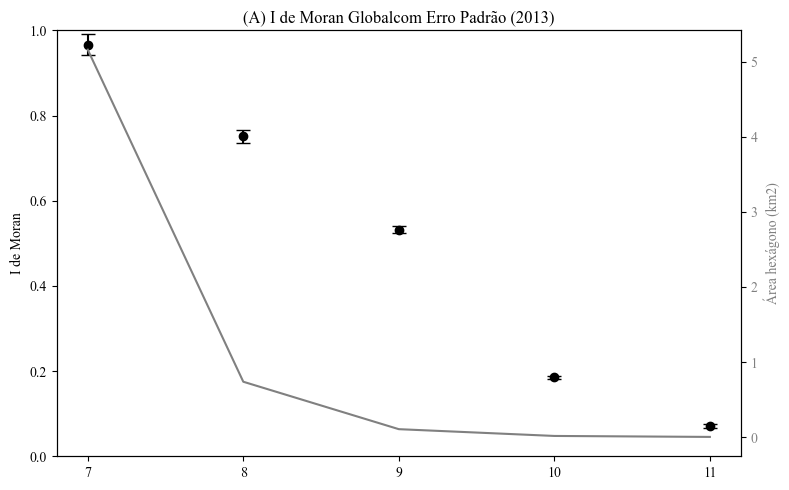

In [33]:
results2013 = pd.DataFrame(morans["2013"])

fig, ax = plt.subplots(figsize=(8, 5))

x = range(len(results2013))
y = results2013["I"]
yerr = results2013["se"]

# Pontos com barras de erro
ax.errorbar(x, y, yerr=yerr, fmt='o', color='black', capsize=5)

# Estética do gráfico
ax.set_xticks(x)
ax.set_xticklabels(results2013["grid"])
ax.set_ylabel("I de Moran")
title = "(A) I de Moran Globalcom Erro Padrão (2013)"
ax.set_title(title)
ax.set_ylim(0, 1)
#ax.grid(True, axis='y', linestyle='-.', alpha=0.6)
#ax.axhline(y=0.966577490007146, alpha=0.85, linestyle=':', c='black')

ax2 = ax.twinx()
ax2.plot(x, [5.161293, 0.737327598, 0.10533251, 0.015047502, 0.00214964], color='gray')
ax2.set_ylabel("Área hexágono (km2)", color='gray')
ax2.tick_params(axis='y', labelcolor='gray')
#ax2.set_ylim(0, 6)

plt.tight_layout()
plt.savefig(f"{title}_job.png", dpi=900)
plt.show()

In [34]:
morans["2021"][0]

{'grid': 7,
 'I': 0.9671376388379251,
 'se': 0.02879871968862657,
 'IC_low': -0.05747745422994132,
 'IC_high': 0.05541352694947483}

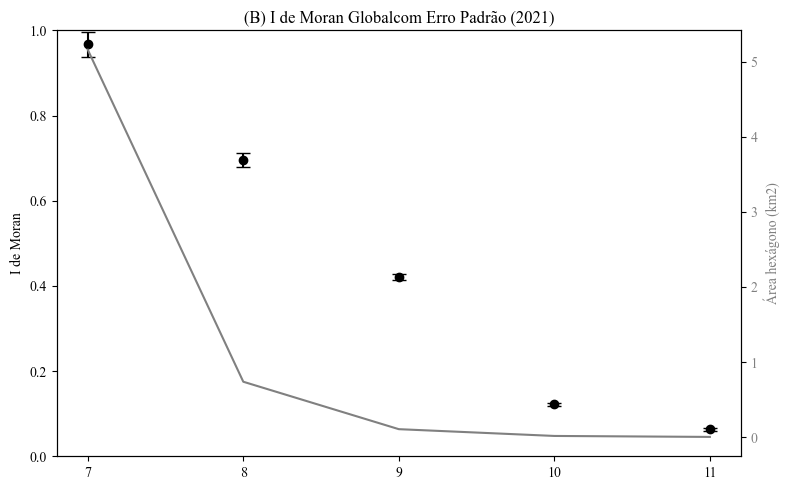

In [35]:
results2021 = pd.DataFrame(morans["2021"])

# Plotar
fig, ax = plt.subplots(figsize=(8, 5))

x = range(len(results2021))
y = results2021["I"]
yerr = results2021["se"]

# Pontos com barras de erro
ax.errorbar(x, y, yerr=yerr, fmt='o', color='black', capsize=5)

# Estética do gráfico
ax.set_xticks(x)
ax.set_xticklabels(results2021["grid"])
ax.set_ylabel("I de Moran")
title = "(B) I de Moran Globalcom Erro Padrão (2021)"
ax.set_title(title)
ax.set_ylim(0, 1)
#ax.grid(True, axis='y', linestyle='-.', alpha=0.6)
#ax.axhline(y=0.9671376388379251, alpha=0.85, linestyle=':', c='black')

ax2 = ax.twinx()
ax2.plot(x, [5.161293, 0.737327598, 0.10533251, 0.015047502, 0.00214964], color='gray')
ax2.set_ylabel("Área hexágono (km2)", color='gray')
ax2.tick_params(axis='y', labelcolor='gray')

plt.tight_layout()
plt.savefig(f"{title}_job.png", dpi=900)

plt.show()

In [ ]:
morans['2013'][0]

({'grid': 7,
  'I': 0.966577490007146,
  'se': 0.02404276144287725,
  'IC_low': -0.04877567426839284,
  'IC_high': 0.04547195058768598},
 {'grid': 10,
  'I': 0.185301556324182,
  'se': 0.003732800124353021,
  'IC_low': -0.007503216209919487,
  'IC_high': 0.007129360277544354})

In [10]:
morans['2021'][0]

{'grid': 7,
 'I': 0.9671376388379251,
 'se': 0.02879871968862657,
 'IC_low': -0.05747745422994132,
 'IC_high': 0.05541352694947483}